# Rule-Based Sentiment Analysis of Video Comments

In [9]:
%pip install -q pandas matplotlib scikit-learn vaderSentiment


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [10]:
from pathlib import Path
import math
import re

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import accuracy_score, confusion_matrix, precision_recall_fscore_support
from sklearn.model_selection import StratifiedKFold, train_test_split
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

SEED = 42
CLASS_ORDER = ['negative', 'neutral', 'positive']

def find_project_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / 'Topic Modeling Rerun' / 'topics_train (2).csv').is_file():
            return candidate
    raise FileNotFoundError(
        'Could not locate Topic Modeling Rerun/topics_train (2).csv. Run this notebook inside the project folder.'
    )

PROJECT_ROOT = find_project_root(Path.cwd().resolve())
SENTIMENT_DIR = PROJECT_ROOT / 'sentiment_analysis'
OUTPUT_DIR = SENTIMENT_DIR / 'outputs'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
TOPIC_DIR = PROJECT_ROOT / 'Topic Modeling Rerun'
TRAIN_PATH = TOPIC_DIR / 'topics_train (2).csv'
HOLDOUT_PATH = TOPIC_DIR / 'topics_holdout (1).csv'

print(f'Project root: {PROJECT_ROOT}')
print(f'Topic input directory: {TOPIC_DIR}')
print(f'Output directory: {OUTPUT_DIR}')

Project root: C:\Users\gerar\Downloads\CSE 15 DATA MINING\Midterm Act 1
Topic input directory: C:\Users\gerar\Downloads\CSE 15 DATA MINING\Midterm Act 1\Topic Modeling Rerun
Output directory: C:\Users\gerar\Downloads\CSE 15 DATA MINING\Midterm Act 1\sentiment_analysis\outputs


## 1. Load topic-annotated comments

All rows from both topic partitions are included, regardless of language or whether the comment is blank. We preserve `original_text`, but remove emoji characters when making `sentiment_text`; no other text cleaning, translation, or contraction expansion is performed. Both the rule-based classifier and VADER receive this emoji-free text, so emojis do not affect either set of sentiment scores. Missing values are represented as empty strings for scoring. The rule lexicon is English-based, so results for other languages should be interpreted cautiously.

In [11]:
train_df = pd.read_csv(TRAIN_PATH)
holdout_df = pd.read_csv(HOLDOUT_PATH)
train_df['topic_model_partition'] = 'topic_train'
holdout_df['topic_model_partition'] = 'topic_holdout'
df = pd.concat([train_df, holdout_df], ignore_index=True)

required_columns = {
    'document_id', 'platform', 'original_text', 'lda_label', 'bt_label'
}
missing_columns = required_columns.difference(df.columns)
if missing_columns:
    raise ValueError(f'Topic files are missing required columns: {sorted(missing_columns)}')

overlapping_ids = set(train_df['document_id']).intersection(holdout_df['document_id'])
if overlapping_ids:
    raise ValueError(f'{len(overlapping_ids)} document IDs occur in both topic partitions.')

df = df.reset_index(drop=True)
EMOJI_PATTERN = re.compile(
    r'[\U0001F000-\U0001FAFF\u2300-\u23FF\u2600-\u27BF'
    r'\uFE0E\uFE0F\u200D\u20E3\U000E0020-\U000E007F]'
)
df['sentiment_text'] = df['original_text'].fillna('').astype(str).map(
    lambda text: EMOJI_PATTERN.sub('', text)
)
assert EMOJI_PATTERN.sub('', 'I love it 😍') == 'I love it '
assert EMOJI_PATTERN.sub('', 'I love it') == 'I love it'

print(f'Topic-model comments included: {len(df):,}')
print(f'Blank original-text rows retained: {df["sentiment_text"].eq("").sum():,}')
print('All languages are retained; sentiment_text removes emojis only, while original_text remains unchanged.')
print('\nTopic-model partitions:')
print(df['topic_model_partition'].value_counts())
print('\nPlatforms:')
print(df['platform'].value_counts())
display(df[['document_id', 'platform', 'sentiment_text', 'lda_label', 'bt_label']].head())

Topic-model comments included: 881
Blank original-text rows retained: 0
All languages are retained; sentiment_text removes emojis only, while original_text remains unchanged.

Topic-model partitions:
topic_model_partition
topic_train      792
topic_holdout     89
Name: count, dtype: int64

Platforms:
platform
TikTok     645
YouTube    236
Name: count, dtype: int64


,document_id,platform,sentiment_text,lda_label,bt_label
0,DOC_002487,TikTok,Go watch the Spain seasons. This is NOTHINGGG,"Recommendations, Promo & Self-Reflection",ASK GROUP TOM.
1,DOC_000978,TikTok,Daniel is the Michael of Billionare you dont nkow,Relating to Characters & Their Stories,ASK GROUP TOM.
2,DOC_000878,TikTok,check my page fors for ai movies also,"Recommendations, Promo & Self-Reflection",ASK GROUP TOM.
3,DOC_001078,TikTok,How I remember those scenes from the Avatar le...,Character Reactions & Pop-Culture References,ASK GROUP TOM.
4,DOC_002039,TikTok,So is he called marco de marco??,"Recommendations, Promo & Self-Reflection",ASK GROUP TOM.


## 2. Rule-based sentiment classifier

The classifier searches the comment text for English sentiment words and negators. Emoji are removed from the scoring text before both the rule-based classifier and VADER are run; the original text remains in its source column. The classifier tokenizes contractions internally so forms such as `don't` can still be recognized.

In [12]:
POSITIVE_WORDS = {
    'amazing', 'awesome', 'beautiful', 'best', 'brilliant', 'enjoy', 'enjoyed',
    'excellent', 'excited', 'favorite', 'fun', 'funny', 'glad', 'good', 'great',
    'happy', 'heartwarming', 'hope', 'impressive', 'interesting', 'love', 'loved',
    'lovely', 'nice', 'perfect', 'recommend', 'sweet', 'thank', 'thanks', 'wonderful',
    'wow', 'better', 'beautifully', 'adorable', 'cute', 'bravo', 'incredible',
    'enjoying', 'liked', 'like', 'charming', 'inspiring', 'favorite', 'support'
}
NEGATIVE_WORDS = {
    'annoying', 'angry', 'awful', 'bad', 'boring', 'confused', 'confusing',
    'cruel', 'disappointed', 'disappointing', 'hate', 'hated', 'horrible', 'hurt',
    'irritating', 'mad', 'mess', 'pain', 'poor', 'sad', 'stupid', 'tired',
    'tiring', 'terrible', 'ugly', 'unfortunately', 'waste', 'weird', 'worst',
    'wrong', 'sucks', 'dislike', 'unhappy', 'ridiculous', 'problem', 'fail', 'failed'
}
NEGATORS = {
    'not', 'no', 'never', 'neither', 'nor', 'hardly', 'barely', 'cannot',
    'dont', 'doesnt', 'didnt', 'isnt', 'wasnt', 'werent', 'wont', 'wouldnt',
    'shouldnt', 'couldnt', 'cant', 'aint', "don't", "doesn't", "didn't",
    "isn't", "wasn't", "weren't", "won't", "wouldn't", "shouldn't",
    "couldn't", "can't", "ain't", "haven't", "hasn't", "hadn't",
    "mustn't", "mightn't", "needn't", "shan't"
}
INTENSIFIERS = {'very', 'really', 'extremely', 'so', 'absolutely', 'totally', 'super'}
DOWNTONERS = {'slightly', 'somewhat', 'rather', 'barely', 'little'}
def rule_sentiment(text: str) -> tuple[float, str]:
    tokens = [token.replace('\u2019', "'") for token in re.findall(r"[a-z]+(?:['\u2019][a-z]+)?", text.lower())]
    score = 0.0
    for index, token in enumerate(tokens):
        if token in POSITIVE_WORDS:
            word_score = 1.0
        elif token in NEGATIVE_WORDS:
            word_score = -1.0
        else:
            continue

        previous = tokens[max(0, index - 3):index]
        if any(word in NEGATORS for word in previous):
            word_score *= -1.0
        if any(word in INTENSIFIERS for word in previous):
            word_score *= 1.5
        elif any(word in DOWNTONERS for word in previous):
            word_score *= 0.5
        score += word_score

    normalized_score = score / math.sqrt(max(1, len(tokens)))
    if normalized_score > 0.15:
        label = 'positive'
    elif normalized_score < -0.15:
        label = 'negative'
    else:
        label = 'neutral'
    return normalized_score, label

assert rule_sentiment('This is not good')[1] == 'negative'
assert rule_sentiment('This is not bad')[1] == 'positive'
assert rule_sentiment("I don't hate it")[1] == 'positive'
assert rule_sentiment('I don\u2019t hate it')[1] == 'positive'

rule_results = df['sentiment_text'].map(rule_sentiment)
df['rule_score'] = rule_results.map(lambda result: result[0])
df['rule_sentiment'] = rule_results.map(lambda result: result[1])

vader = SentimentIntensityAnalyzer()
df['vader_compound'] = df['sentiment_text'].map(
    lambda text: vader.polarity_scores(text)['compound']
)
df['vader_reference'] = pd.cut(
    df['vader_compound'],
    bins=[-1.000001, -0.05, 0.05, 1.000001],
    labels=['negative', 'neutral', 'positive'],
    include_lowest=True
).astype(str)

display(df[['sentiment_text', 'rule_score', 'rule_sentiment', 'vader_compound', 'vader_reference']].head(10))
print('Rule-based sentiment counts:')
display(df['rule_sentiment'].value_counts().reindex(CLASS_ORDER, fill_value=0).to_frame('comments'))

,sentiment_text,rule_score,rule_sentiment,vader_compound,vader_reference
0,Go watch the Spain seasons. This is NOTHINGGG,0.000000,neutral,0.0000,neutral
1,Daniel is the Michael of Billionare you dont nkow,0.000000,neutral,0.0000,neutral
2,check my page fors for ai movies also,0.000000,neutral,0.0000,neutral
3,How I remember those scenes from the Avatar le...,0.000000,neutral,0.4019,positive
4,So is he called marco de marco??,0.000000,neutral,0.0000,neutral
5,Abeg kill Micheal and let Cynthia enjoy in peace,0.333333,positive,0.2500,positive
6,I almost forget about this story sef,0.000000,neutral,-0.1548,negative
7,Every clip I have seen of Montoya has been aga...,0.000000,neutral,0.5106,positive
8,"mark is a girls girl, we love mark",0.353553,positive,0.6369,positive
9,Such a deep abandonment wound she has . I’m ve...,0.246598,positive,0.7232,positive


Rule-based sentiment counts:


,comments
rule_sentiment,
negative,73
neutral,560
positive,248


## 3. 90/10 unseen-data evaluation

The holdout metrics compare the rule-based labels with VADER's weak-reference labels; there are no human-annotated labels. Since all original comments are included, these figures summarize agreement for the full mixed-language dataset and should be treated cautiously for non-English comments.

Training partition: 792; unseen test partition: 89


,n_comments,accuracy,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1
evaluation,,,,,,,,
90/10 unseen holdout,89,0.64,0.763,0.648,0.604,0.822,0.64,0.644


,class,precision,recall,f1,support
0,negative,0.875,0.292,0.438,24
1,neutral,0.415,1.000,0.587,22
2,positive,1.000,0.651,0.789,43


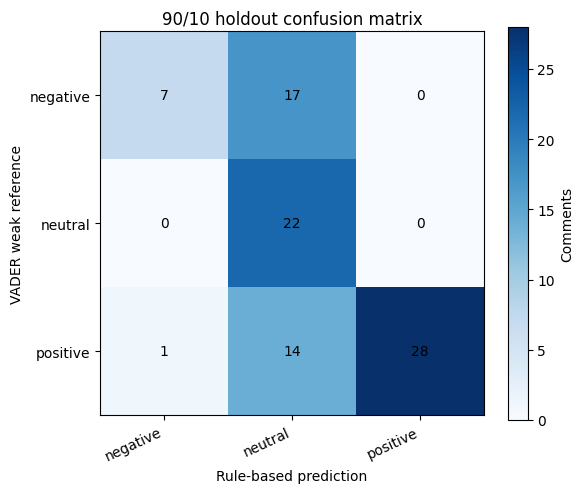

In [13]:
reference = df['vader_reference'].astype(str)
predicted = df['rule_sentiment'].astype(str)
class_counts = reference.value_counts()
if class_counts.min() < 10:
    raise ValueError(
        'At least 10 comments per VADER reference class are required for stratified 10-fold validation.'
    )

row_indices = pd.RangeIndex(len(df))
train_indices, test_indices = train_test_split(
    row_indices,
    test_size=0.10,
    random_state=SEED,
    stratify=reference
)

def evaluate_agreement(y_true: pd.Series, y_pred: pd.Series, name: str) -> tuple[dict, pd.DataFrame]:
    precision, recall, f1, support = precision_recall_fscore_support(
        y_true, y_pred, labels=CLASS_ORDER, zero_division=0
    )
    macro_precision, macro_recall, macro_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=CLASS_ORDER, average='macro', zero_division=0
    )
    weighted_precision, weighted_recall, weighted_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=CLASS_ORDER, average='weighted', zero_division=0
    )
    summary = {
        'evaluation': name,
        'n_comments': len(y_true),
        'accuracy': accuracy_score(y_true, y_pred),
        'macro_precision': macro_precision,
        'macro_recall': macro_recall,
        'macro_f1': macro_f1,
        'weighted_precision': weighted_precision,
        'weighted_recall': weighted_recall,
        'weighted_f1': weighted_f1
    }
    per_class = pd.DataFrame({
        'class': CLASS_ORDER,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'support': support
    })
    return summary, per_class

holdout_summary, holdout_per_class = evaluate_agreement(
    reference.iloc[test_indices], predicted.iloc[test_indices], '90/10 unseen holdout'
)
print(f'Training partition: {len(train_indices):,}; unseen test partition: {len(test_indices):,}')
display(pd.DataFrame([holdout_summary]).set_index('evaluation').round(3))
display(holdout_per_class.round(3))

holdout_matrix = confusion_matrix(
    reference.iloc[test_indices], predicted.iloc[test_indices], labels=CLASS_ORDER
)
fig, ax = plt.subplots(figsize=(6, 5))
image = ax.imshow(holdout_matrix, cmap='Blues')
ax.set_xticks(range(len(CLASS_ORDER)), CLASS_ORDER, rotation=25, ha='right')
ax.set_yticks(range(len(CLASS_ORDER)), CLASS_ORDER)
ax.set_xlabel('Rule-based prediction')
ax.set_ylabel('VADER weak reference')
ax.set_title('90/10 holdout confusion matrix')
for row in range(len(CLASS_ORDER)):
    for column in range(len(CLASS_ORDER)):
        ax.text(column, row, str(holdout_matrix[row, column]), ha='center', va='center')
fig.colorbar(image, ax=ax, label='Comments')
fig.tight_layout()
plt.show()

## 4. Stratified 10-fold validation

Ten stratified folds provide a second estimate of rule-based/VADER agreement across the complete set of included comments. As above, the scores are not human-validated accuracy.

In [14]:
fold_rows = []
out_of_fold_predictions = pd.Series(index=df.index, dtype='object')
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
for fold_number, (_, fold_test_indices) in enumerate(cv.split(df, reference), start=1):
    y_true = reference.iloc[fold_test_indices]
    y_pred = predicted.iloc[fold_test_indices]
    out_of_fold_predictions.iloc[fold_test_indices] = y_pred.to_numpy()
    fold_summary, _ = evaluate_agreement(y_true, y_pred, f'fold_{fold_number}')
    fold_summary['fold'] = fold_number
    fold_rows.append(fold_summary)

fold_metrics = pd.DataFrame(fold_rows)
cv_mean = fold_metrics[['accuracy', 'macro_precision', 'macro_recall', 'macro_f1']].mean()
cv_std = fold_metrics[['accuracy', 'macro_precision', 'macro_recall', 'macro_f1']].std(ddof=1)
cv_summary = pd.DataFrame({'mean': cv_mean, 'std': cv_std})
overall_oof_summary, overall_oof_per_class = evaluate_agreement(
    reference, out_of_fold_predictions.astype(str), '10-fold out-of-fold aggregate'
)

print('10-fold metrics (mean and standard deviation):')
display(cv_summary.round(3))
print('Aggregate out-of-fold metrics:')
display(pd.DataFrame([overall_oof_summary]).set_index('evaluation').round(3))
display(overall_oof_per_class.round(3))
display(fold_metrics[['fold', 'n_comments', 'accuracy', 'macro_precision', 'macro_recall', 'macro_f1']].round(3))

10-fold metrics (mean and standard deviation):


,mean,std
accuracy,0.566,0.043
macro_precision,0.718,0.028
macro_recall,0.582,0.039
macro_f1,0.536,0.047


Aggregate out-of-fold metrics:


,n_comments,accuracy,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1
evaluation,,,,,,,,
10-fold out-of-fold aggregate,881,0.566,0.713,0.582,0.539,0.762,0.566,0.568


,class,precision,recall,f1,support
0,negative,0.849,0.267,0.407,232
1,neutral,0.375,0.946,0.537,222
2,positive,0.915,0.532,0.673,427


,fold,n_comments,accuracy,macro_precision,macro_recall,macro_f1
0,1,89,0.573,0.714,0.573,0.518
1,2,88,0.523,0.694,0.555,0.509
2,3,88,0.568,0.710,0.577,0.526
3,4,88,0.659,0.765,0.666,0.638
4,5,88,0.534,0.743,0.539,0.488
5,6,88,0.591,0.710,0.619,0.582
6,7,88,0.545,0.760,0.569,0.510
7,8,88,0.602,0.687,0.613,0.572
8,9,88,0.545,0.700,0.560,0.531
9,10,88,0.523,0.697,0.546,0.490


## 5. Sentiment by platform and topic

The summaries include all records, including comments in other languages and blank comments. Percentages are calculated within each platform or topic so differently sized groups can be compared; language coverage may affect how well the English-based classifier reflects sentiment.

,comments,percent
rule_sentiment,,
negative,73,8.29
neutral,560,63.56
positive,248,28.15


By platform:


rule_sentiment,negative,neutral,positive,negative_percent,neutral_percent,positive_percent
platform,,,,,,
YouTube,21,114,101,8.90,48.31,42.80
TikTok,52,446,147,8.06,69.15,22.79


By LDA topic:


rule_sentiment,negative,neutral,positive,negative_percent,neutral_percent,positive_percent
lda_label,,,,,,
Relating to Characters & Their Stories,23,167,103,7.85,57.00,35.15
"Recommendations, Promo & Self-Reflection",18,157,60,7.66,66.81,25.53
Character Reactions & Pop-Culture References,32,236,85,9.07,66.86,24.08


By BERTopic topic (including outliers):


rule_sentiment,negative,neutral,positive,negative_percent,neutral_percent,positive_percent
bt_label,,,,,,
ASK GROUP TOM.,73,560,248,8.29,63.56,28.15


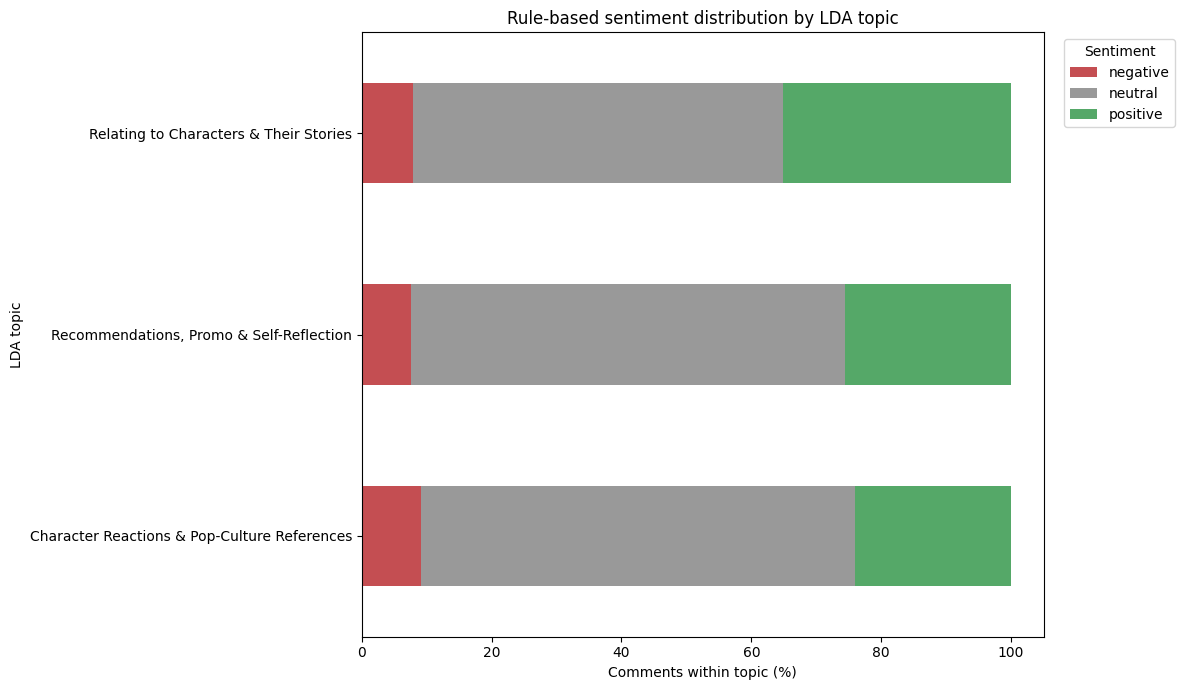

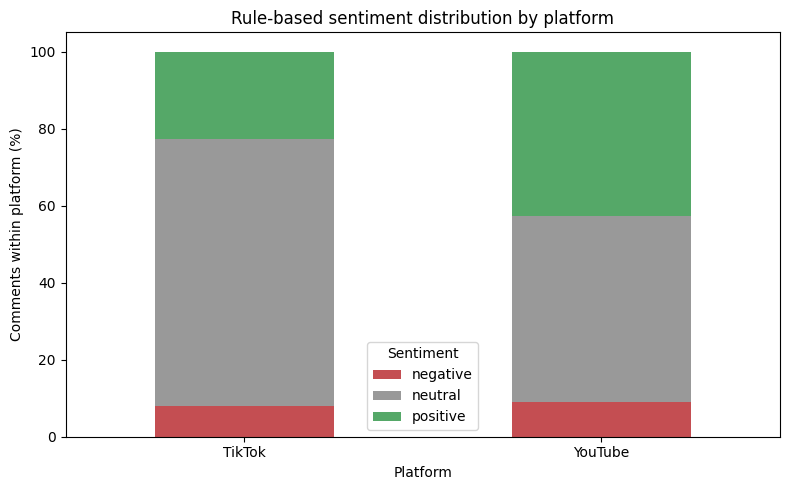

In [15]:
sentiment_counts = df['rule_sentiment'].value_counts().reindex(CLASS_ORDER, fill_value=0)
sentiment_percent = (sentiment_counts / len(df) * 100).rename('percent')
display(pd.concat([sentiment_counts.rename('comments'), sentiment_percent], axis=1).round(2))

def sentiment_breakdown(group_column: str) -> pd.DataFrame:
    counts = pd.crosstab(df[group_column], df['rule_sentiment']).reindex(columns=CLASS_ORDER, fill_value=0)
    percentages = counts.div(counts.sum(axis=1).replace(0, 1), axis=0) * 100
    return counts.join(percentages, rsuffix='_percent').sort_values(
        'positive_percent', ascending=False
    )

platform_breakdown = sentiment_breakdown('platform')
lda_breakdown = sentiment_breakdown('lda_label')
bertopic_breakdown = sentiment_breakdown('bt_label')
print('By platform:')
display(platform_breakdown.round(2))
print('By LDA topic:')
display(lda_breakdown.round(2))
print('By BERTopic topic (including outliers):')
display(bertopic_breakdown.round(2))

topic_percentages = pd.crosstab(
    df['lda_label'], df['rule_sentiment'], normalize='index'
).reindex(columns=CLASS_ORDER, fill_value=0) * 100
topic_percentages = topic_percentages.sort_values('positive', ascending=True)
ax = topic_percentages.plot(
    kind='barh', stacked=True, figsize=(12, 7),
    color={'negative': '#c44e52', 'neutral': '#999999', 'positive': '#55a868'}
)
ax.set_xlabel('Comments within topic (%)')
ax.set_ylabel('LDA topic')
ax.set_title('Rule-based sentiment distribution by LDA topic')
ax.legend(title='Sentiment', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

platform_percentages = pd.crosstab(
    df['platform'], df['rule_sentiment'], normalize='index'
).reindex(columns=CLASS_ORDER, fill_value=0) * 100
ax = platform_percentages.plot(
    kind='bar', stacked=True, figsize=(8, 5),
    color={'negative': '#c44e52', 'neutral': '#999999', 'positive': '#55a868'}
)
ax.set_ylabel('Comments within platform (%)')
ax.set_xlabel('Platform')
ax.set_title('Rule-based sentiment distribution by platform')
ax.legend(title='Sentiment')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [16]:
prediction_columns = [
    'document_id', 'platform', 'sentiment_text', 'topic_model_partition',
    'lda_label', 'bt_label', 'rule_score', 'rule_sentiment',
    'vader_compound', 'vader_reference'
]
predictions_path = OUTPUT_DIR / 'sentiment_predictions.csv'
lda_path = OUTPUT_DIR / 'sentiment_by_lda_topic.csv'
bertopic_path = OUTPUT_DIR / 'sentiment_by_bertopic_topic.csv'
platform_path = OUTPUT_DIR / 'sentiment_by_platform.csv'
metrics_path = OUTPUT_DIR / 'sentiment_evaluation_metrics.csv'

df[prediction_columns].to_csv(predictions_path, index=False)
lda_breakdown.to_csv(lda_path)
bertopic_breakdown.to_csv(bertopic_path)
platform_breakdown.to_csv(platform_path)
metrics = pd.concat([
    pd.DataFrame([holdout_summary]),
    pd.DataFrame([overall_oof_summary])
], ignore_index=True)
metrics.to_csv(metrics_path, index=False)

for output_path in [predictions_path, lda_path, bertopic_path, platform_path, metrics_path]:
    print(f'Saved: {output_path}')

Saved: C:\Users\gerar\Downloads\CSE 15 DATA MINING\Midterm Act 1\sentiment_analysis\outputs\sentiment_predictions.csv
Saved: C:\Users\gerar\Downloads\CSE 15 DATA MINING\Midterm Act 1\sentiment_analysis\outputs\sentiment_by_lda_topic.csv
Saved: C:\Users\gerar\Downloads\CSE 15 DATA MINING\Midterm Act 1\sentiment_analysis\outputs\sentiment_by_bertopic_topic.csv
Saved: C:\Users\gerar\Downloads\CSE 15 DATA MINING\Midterm Act 1\sentiment_analysis\outputs\sentiment_by_platform.csv
Saved: C:\Users\gerar\Downloads\CSE 15 DATA MINING\Midterm Act 1\sentiment_analysis\outputs\sentiment_evaluation_metrics.csv
